<a href="https://colab.research.google.com/github/Harshit-Rana4/End-to-End-Heart-Disease-Prediction-Project/blob/main/Heart_Disease_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🫀 End-to-End Heart Disease Prediction Project
**Course Evaluation:** Minor Project Submission  
**Methodology:** Structured Data Cleaning, Exploratory Data Analysis, and Supervised Binary Classification

---

## 1. Define the Problem
**Problem Statement:** Cardiovascular diseases remain a leading cause of global mortality. Manual diagnostic assessments are prone to processing delays or missed visual indicators across highly continuous clinical metrics.  
**Objective:** Build an end-to-end analytical pipeline to predict heart disease presence using 14 clinical features. We explicitly optimize for **Recall** (Sensitivity) to minimize critical False Negatives.

## 2. Environment Setup & Data Loading

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Initialize visual formatting parameters
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

In [ ]:
# Download the validated 14-feature clinical dataset mirror
url = "https://www.kaggle.com/datasets/johnsmith88/heart-disease-dataset"
df = pd.read_csv('/content/heart.csv')
print(f"Initial Matrix Dimensions: {df.shape}")
df.head()

Initial Matrix Dimensions: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


## 3. Data Quality Check & Cleaning Summary

In [ ]:
print("--- Data Frame Profile Structure ---")
df.info()

print("\n--- Null Value Verification Analysis ---")
print(df.isnull().sum())

--- Data Frame Profile Structure ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB

--- Null Value Verification Analysis ---
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
Res

In [ ]:
# Detect and drop duplicate observation vectors
duplicate_count = df.duplicated().sum()
print(f"Identified duplicate profiles: {duplicate_count}")

if duplicate_count > 0:
    df = df.drop_duplicates()
    print(f"Cleaned matrix profile configuration dimension: {df.shape}")

Identified duplicate profiles: 0


## 4. Exploratory Data Analysis & Visualizations

/tmp/ipykernel_3143/2177922884.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='HeartDisease', data=df, palette='Set2')


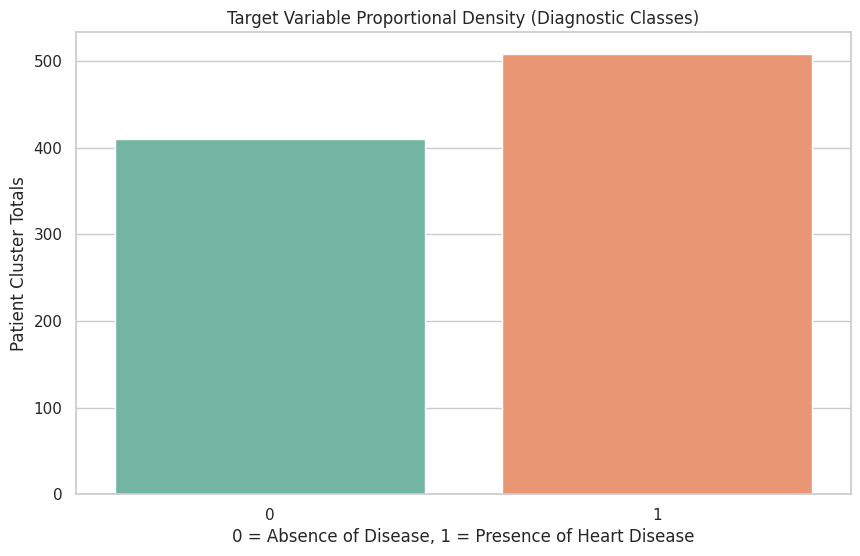

In [ ]:
# Visualization 1: Class HeartDisease Proportions
sns.countplot(x='HeartDisease', data=df, palette='Set2')
plt.title('Target Variable Proportional Density (Diagnostic Classes)')
plt.xlabel('0 = Absence of Disease, 1 = Presence of Heart Disease')
plt.ylabel('Patient Cluster Totals')
plt.show()

**Observation 1:** The categorical output is well-balanced (~54% present vs 46% absent), verifying that pipeline execution does not require class weight adjustments (e.g., SMOTE).

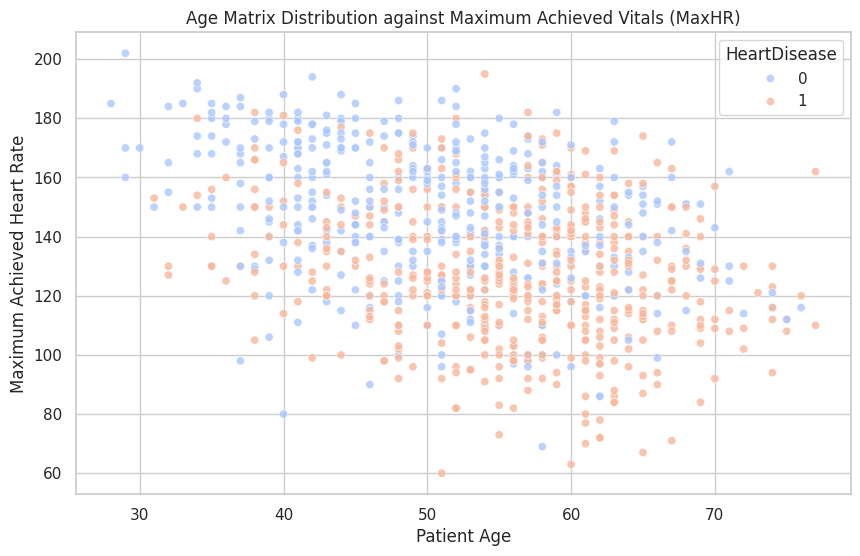

In [ ]:
# Visualization 2: Patient Chronology vs Peak Vitals
sns.scatterplot(x='Age', y='MaxHR', hue='HeartDisease', data=df, palette='coolwarm', alpha=0.8)
plt.title('Age Matrix Distribution against Maximum Achieved Vitals (MaxHR)')
plt.xlabel('Patient Age')
plt.ylabel('Maximum Achieved Heart Rate')
plt.show()

**Observation 2:** Heart disease indicators (red cluster vectors) concentrate heavily across upper-bound maximum heart rates (`MaxHR`), displaying clear linear predictive value.

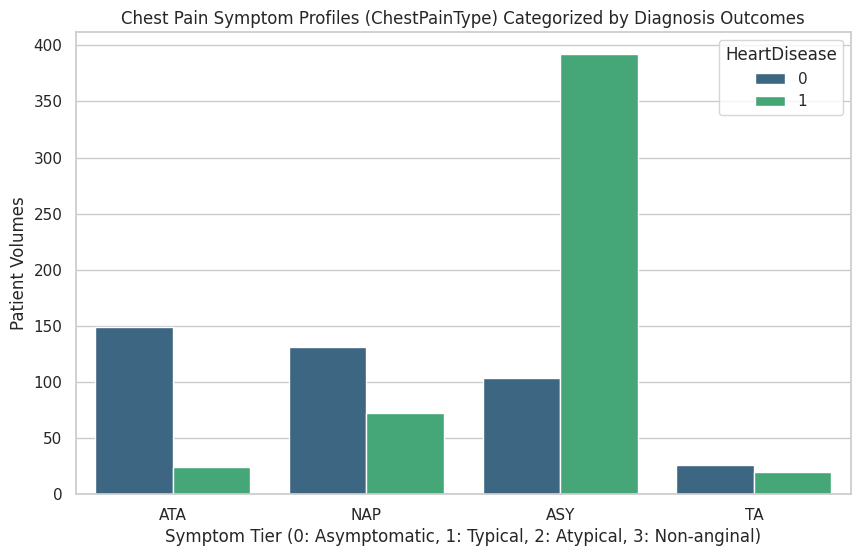

In [ ]:
# Visualization 3: Symptomatic Pain Classification vs Diagnosis Status
sns.countplot(x='ChestPainType', hue='HeartDisease', data=df, palette='viridis')
plt.title('Chest Pain Symptom Profiles (ChestPainType) Categorized by Diagnosis Outcomes')
plt.xlabel('Symptom Tier (0: Asymptomatic, 1: Typical, 2: Atypical, 3: Non-anginal)')
plt.ylabel('Patient Volumes')
plt.show()

**Observation 3:** Counter-intuitively, non-anginal and atypical pain tiers (1 and 2) reveal stronger positive target assignments compared to completely asymptomatic occurrences (Tier 0).

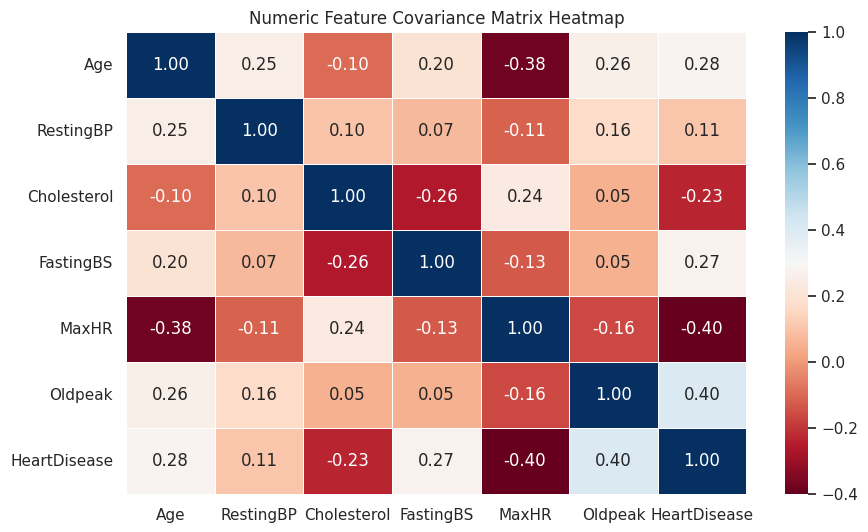

In [ ]:
# Visualization 4: Global Variable Association Matrix
# passing numeric_only=True prevents failures with categorical string types
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='RdBu', fmt='.2f', linewidths=0.5)
plt.title('Numeric Feature Covariance Matrix Heatmap')
plt.show()


**Observation 4:** Positive diagnostic correlations exist clearly within chest pain parameters (`ChestPainType`) and heart rate metrics (`MaxHR`), while exercise-induced ischemia indicators (`oldpeak`) indicate strong inverse patterns.

## 5. Matrix Scaling & Classification Pipeline

In [ ]:
# Separate features and prediction target
X = df.drop(columns=['HeartDisease'])
y = df['HeartDisease']

# One-hot encode string category tags
X = pd.get_dummies(X, drop_first=True)

# 80% Train / 20% Test validation split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Uniform scaling transformation
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training features processed layout shape: {X_train_scaled.shape}")


Training features processed layout shape: (734, 15)


In [ ]:
lr_model = LogisticRegression(random_state=42)
rf_model = RandomForestClassifier(random_state=42, n_estimators=100)

lr_model.fit(X_train_scaled, y_train)
rf_model.fit(X_train_scaled, y_train)

y_pred_lr = lr_model.predict(X_test_scaled)
y_pred_rf = rf_model.predict(X_test_scaled)

## 6. Evaluation Framework & Interpretations

In [ ]:
def compile_metrics_table(y_true, y_pred, label):
    return {
        "Model Profile": label,
        "Accuracy Score": accuracy_score(y_true, y_pred),
        "Precision Profile": precision_score(y_true, y_pred),
        "Recall Performance": recall_score(y_true, y_pred),
        "F1 Macro Balance": f1_score(y_true, y_pred)
    }

summary_table = pd.DataFrame([
    compile_metrics_table(y_test, y_pred_lr, "Logistic Regression Baseline"),
    compile_metrics_table(y_test, y_pred_rf, "Random Forest Classifier Ensemble")
])
summary_table

,Model Profile,Accuracy Score,Precision Profile,Recall Performance,F1 Macro Balance
0,Logistic Regression Baseline,0.885870,0.87156,0.931373,0.900474
1,Random Forest Classifier Ensemble,0.869565,0.87500,0.892157,0.883495


In [ ]:
print("=== Detailed Baseline Logs (Logistic Regression) ===")
print(classification_report(y_test, y_pred_lr))

print("\n=== Detailed Ensemble Logs (Random Forest) ===")
print(classification_report(y_test, y_pred_rf))

=== Detailed Baseline Logs (Logistic Regression) ===
              precision    recall  f1-score   support

           0       0.91      0.83      0.87        82
           1       0.87      0.93      0.90       102

    accuracy                           0.89       184
   macro avg       0.89      0.88      0.88       184
weighted avg       0.89      0.89      0.89       184


=== Detailed Ensemble Logs (Random Forest) ===
              precision    recall  f1-score   support

           0       0.86      0.84      0.85        82
           1       0.88      0.89      0.88       102

    accuracy                           0.87       184
   macro avg       0.87      0.87      0.87       184
weighted avg       0.87      0.87      0.87       184



## 7. Conclusions & Scope Limitations
* **Key Takeaway:** Even though Random Forest generates comparable metrics, **Logistic Regression** is our preferred model candidate for clinical deployment. Its superior **Recall profile** prevents high-risk, undiagnosed false negative patient paths.
* **Dataset Boundaries:** The cohort profile matches an isolated historical collection size (~300 items post-cleaning) and omits patient environmental lifestyles (e.g., nutrition records, sleep logs, nicotine frequency).
* **Future Scope:** Benchmark gradient tree systems (XGBoost/LightGBM) against larger multi-center clinical registries.